# Notebook 3: Model Training and Validation
This notebook trains the 24-hour-ahead forecasting model on the feature table from Notebook 2, validates it on a held-out period, compares it with simple baselines, explains which features matter, and saves the trained models.

## 1. Setup
We load the feature table and group the features by source (calendar, season, holidays, lags, weather) so that the contribution of each group can be measured separately.

In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
features_df = pd.read_csv("data/features_30min.csv", index_col="Datetime", parse_dates=True)

TARGET = "Total_Load"

calendar_features = ["block", "dayofweek", "is_weekend", "block_sin", "block_cos", "dow_sin", "dow_cos"]
season_features = ["month", "dayofyear", "month_sin", "month_cos"]
holiday_features = ["is_holiday", "is_national", "is_festival", "is_tribal", "is_industrial",
                    "is_day_before_holiday", "is_day_after_holiday"]
lag_features = ["lag_48", "lag_96", "lag_336", "mean_prev_24h"]
weather_features = ["temp_c", "humidity_pct", "cloud_cover_pct", "wind_kmh",
                    "temp_roll_3h", "temp_roll_24h", "temp_x_humidity"]

print("Rows:", len(features_df))
print("Period:", features_df.index.min(), "to", features_df.index.max())
features_df[[TARGET] + lag_features].head(3)

Rows: 17136
Period: 2017-01-08 00:00:00 to 2017-12-30 23:30:00


,Total_Load,lag_48,lag_96,lag_336,mean_prev_24h
Datetime,,,,,
2017-01-08 00:00:00,64181.578557,64574.087063,64522.30228,69183.200413,68334.166444
2017-01-08 00:30:00,59672.437197,60201.143030,60260.37895,63770.340780,68332.932363
2017-01-08 01:00:00,56362.712693,56377.789120,56274.78917,59511.577067,68335.078195


## 2. Train / Test Split
Time-series data must be split by time, never randomly: a random split would put neighbouring half-hours of the same day into both sets and make the model look better than it really is. We train on 8 January - 31 October and test on 1 November - 30 December, a period the model has never seen.

In [3]:
train = features_df.loc[:"2017-10-31 23:30"]
test = features_df.loc["2017-11-01":]

print("Train:", train.index.min().date(), "to", train.index.max().date(), "|", len(train), "blocks")
print("Test :", test.index.min().date(), "to", test.index.max().date(), "|", len(test), "blocks")

Train: 2017-01-08 to 2017-10-31 | 14256 blocks
Test : 2017-11-01 to 2017-12-30 | 2880 blocks


## 3. Baselines
Any model must beat simple rules. We use two: "the same time yesterday" and "the same time last week". Metrics: MAE and RMSE in kW, and MAPE in percent.

In [4]:
def evaluate(y_true, y_pred):
    """Return MAE, RMSE (both in kW) and MAPE (in %)."""
    mae = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return {"MAE": round(mae), "RMSE": round(rmse), "MAPE %": round(mape, 2)}

y_test = test[TARGET]

baselines = pd.DataFrame({
    "same time yesterday (lag_48)": evaluate(y_test, test["lag_48"]),
    "same time last week (lag_336)": evaluate(y_test, test["lag_336"]),
}).T
baselines

,MAE,RMSE,MAPE %
same time yesterday (lag_48),2098.0,3212.0,3.37
same time last week (lag_336),2129.0,2959.0,3.38


## 4. Which Feature Groups Help?
We train the same model on progressively richer feature sets and compare the test error. This turns the EDA findings into evidence: each group is kept only if it improves the forecast.

In [5]:
feature_sets = {
    "A: calendar only": calendar_features,
    "B: calendar + season": calendar_features + season_features,
    "C: calendar + lags": calendar_features + lag_features,
    "D: calendar + lags + holidays": calendar_features + lag_features + holiday_features,
    "E: calendar + lags + holidays + weather": calendar_features + lag_features + holiday_features + weather_features,
    "F: all features": calendar_features + season_features + lag_features + holiday_features + weather_features,
}

def make_model():
    return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=42)

results = {}
for name, cols in feature_sets.items():
    model = make_model().fit(train[cols], train[TARGET])
    results[name] = evaluate(y_test, model.predict(test[cols]))

comparison = pd.DataFrame(results).T
comparison

,MAE,RMSE,MAPE %
A: calendar only,9201.0,9950.0,14.88
B: calendar + season,2874.0,3597.0,4.71
C: calendar + lags,1526.0,2176.0,2.42
D: calendar + lags + holidays,1482.0,2133.0,2.36
E: calendar + lags + holidays + weather,1473.0,2103.0,2.33
F: all features,1448.0,2057.0,2.29


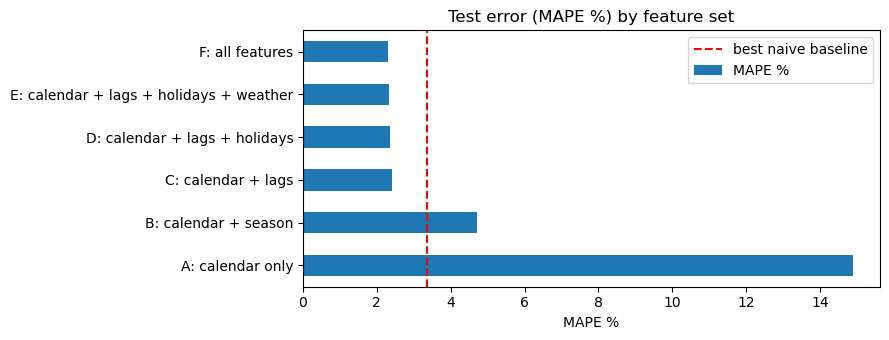

In [6]:
comparison["MAPE %"].plot(kind="barh", figsize=(9, 3.5), title="Test error (MAPE %) by feature set")
plt.axvline(baselines["MAPE %"].min(), color="red", linestyle="--", label="best naive baseline")
plt.xlabel("MAPE %")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Final Model Evaluation
The feature set with the lowest test error is selected automatically. We then look at the predictions in detail: actual vs predicted for one week, and the error by time of day.

In [7]:
best_name = comparison["MAPE %"].idxmin()
best_features = feature_sets[best_name]
print("Selected feature set:", best_name, "| number of features:", len(best_features))

model = make_model().fit(train[best_features], train[TARGET])
test_pred = pd.Series(model.predict(test[best_features]), index=test.index)

print(evaluate(y_test, test_pred))
gain = 1 - comparison.loc[best_name, "MAPE %"] / baselines["MAPE %"].min()
print(f"Error reduction compared with the best naive baseline: {gain:.0%}")

Selected feature set: F: all features | number of features: 29
{'MAE': 1448, 'RMSE': 2057, 'MAPE %': np.float64(2.29)}
Error reduction compared with the best naive baseline: 32%


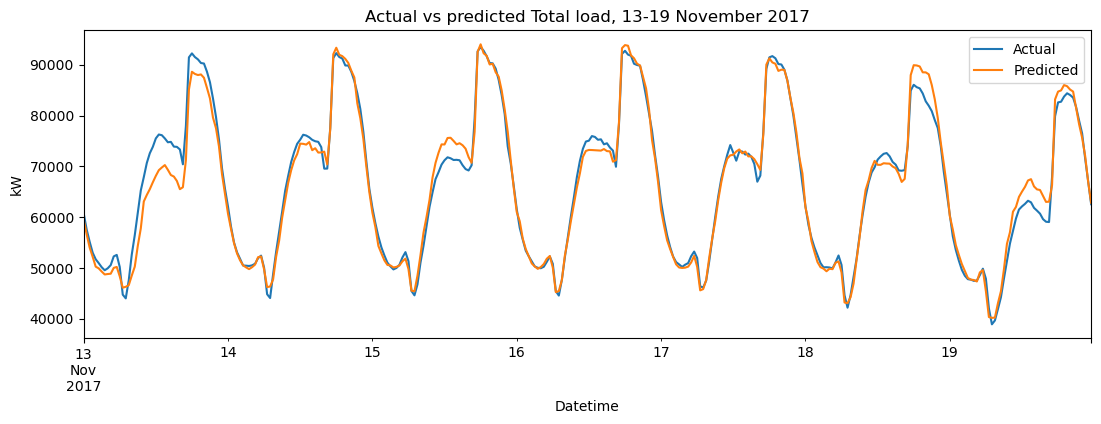

In [8]:
week = slice("2017-11-13", "2017-11-19")
fig, ax = plt.subplots(figsize=(13, 4))
y_test[week].plot(ax=ax, label="Actual")
test_pred[week].plot(ax=ax, label="Predicted")
ax.set_title("Actual vs predicted Total load, 13-19 November 2017")
ax.set_ylabel("kW")
ax.legend()
plt.show()

**Observation:** The predicted curve follows the actual load closely through the whole week: the night minimum (about 45-50k kW), the daytime plateau (about 70-75k kW) and the sharp evening rise to about 90k kW are all reproduced, and the lower level on the weekend is captured. The largest gaps appear on Monday 13 November, where the daytime load and the evening peak are under-predicted by roughly 4-6k kW, and on Sunday 19 November, where the daytime load is slightly over-predicted. Gaps are largest right after a sudden change in load.

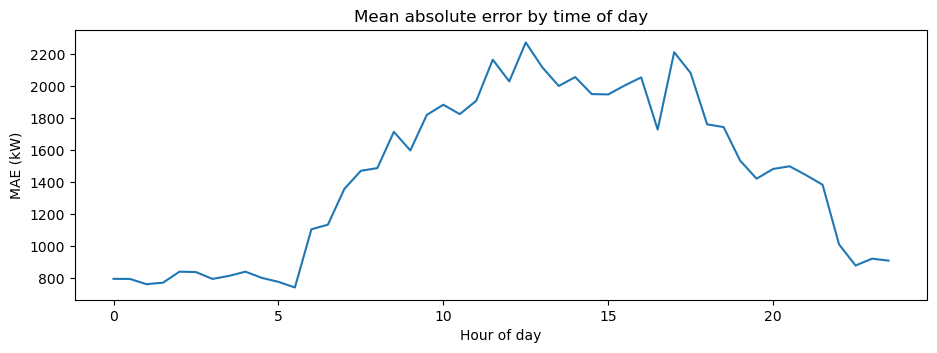

Hardest time of day: 12.5 h | MAE 2271


In [9]:
error = (y_test - test_pred).abs()
error_by_block = error.groupby(test.index.hour + test.index.minute / 60).mean()

plt.figure(figsize=(11, 3.5))
plt.plot(error_by_block.index, error_by_block.values)
plt.title("Mean absolute error by time of day")
plt.xlabel("Hour of day")
plt.ylabel("MAE (kW)")
plt.show()

print("Hardest time of day:", error_by_block.idxmax(), "h | MAE", round(error_by_block.max()))

**Observation:** The error is not constant through the day. It is largest around 12:30 (MAE about 2,270 kW), when the load is changing most quickly, and smaller during the stable night hours. This is where further improvement would be most valuable.

## 6. Which Features Matter?
Permutation importance shuffles one feature at a time on the test set and measures how much the error grows. A large increase means the model relies on that feature.

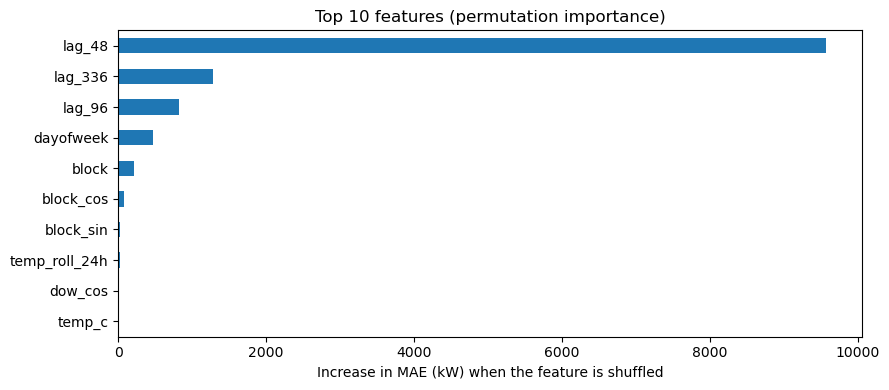

In [10]:
importance = permutation_importance(model, test[best_features], y_test,
                                    n_repeats=5, random_state=42, scoring="neg_mean_absolute_error")
importance_df = pd.Series(importance.importances_mean, index=best_features).sort_values()

importance_df.tail(10).plot(kind="barh", figsize=(9, 4), title="Top 10 features (permutation importance)")
plt.xlabel("Increase in MAE (kW) when the feature is shuffled")
plt.tight_layout()
plt.show()

**Observation:** The model relies overwhelmingly on the load of the same time yesterday (lag_48): shuffling it raises the error by about 9,500 kW, far more than any other feature. The weekly lag (lag_336), the two-day lag (lag_96), the day of the week and the time of day follow. Weather and holiday features have a much smaller individual importance, which matches the weak weather correlation and modest holiday effect found in the EDA; their value is the small accuracy gain seen in the feature-set comparison. Permutation importance can understate features that are correlated with others (such as the three lag features), so the ranking is indicative rather than exact.

## 7. Why This Model?

**Task.** Predict the next 24 hours of load in 30-minute blocks, so the model must work with information available at forecast time (lags of at least 24 hours, calendar, holidays and weather forecasts).

**Evidence from the EDA that drives the choice**
- Very high autocorrelation at 24 h (0.98) and 7 days (0.97) -> lag features at 48 and 336 blocks.
- A strong, non-linear daily cycle and a seasonal swing -> calendar and season features with cyclical encoding.
- Weak and non-linear relation with weather, and holiday effects only on specific days -> a model that can learn interactions and selective effects without hand-made formulas.

**Why gradient-boosted trees.** They handle non-linear effects and feature interactions automatically, need no scaling, are robust to a few unusual events (the 20 April level shift of F1 and the July evening peaks), train in seconds on 17k rows and are easy to deploy. A linear model would miss the non-linear daily and seasonal shape, and an LSTM would need far more data than one year to beat gradient boosting while being harder to explain and deploy.

**Evidence.** The best naive baseline (same time yesterday) has a MAPE of 3.37%. The selected model (all features) reaches a MAPE of 2.29%, an error reduction of 32%. Calendar-only features give 14.9%, adding lag features brings it to 2.4%, holidays add a small further gain (2.36%), Dhanbad weather improves it again (2.33%) and season features give the best result (2.29%). Each group therefore helps, although the gains from holidays, weather and season are small compared with the lags, consistent with the EDA (weak weather correlation, modest holiday effect).

**Limitations.** Only one year of data, so seasonality cannot be validated across years; the test period (Nov-Dec) is only two months; lunar-festival dates must be refreshed each year. The feature set was chosen on the same test period, and the differences between the last three sets (about 0.05 percentage points) are small, so they should be confirmed on additional data.

## 8. Feeder Models and Saving
The same pipeline is applied to each feeder (with its own lags), giving four models: Total_Load, F1, F2 and F3. The final models are trained on all available data and saved for the API.

In [11]:
full_load = pd.read_csv("data/load_clean_30min.csv", index_col="Datetime", parse_dates=True)

feeder_columns = {
    "Total_Load": "Total_Load",
    "F1": "F1_132KV_PowerConsumption",
    "F2": "F2_132KV_PowerConsumption",
    "F3": "F3_132KV_PowerConsumption",
}

def lags_for(series):
    """Same lag features as before, built from any load series."""
    return pd.DataFrame({
        "lag_48": series.shift(48),
        "lag_96": series.shift(96),
        "lag_336": series.shift(336),
        "mean_prev_24h": series.shift(48).rolling(48).mean(),
    })

base_cols = [c for c in best_features if c not in lag_features]
models = {}
metrics = {}

for name, column in feeder_columns.items():
    data = features_df[base_cols].join(lags_for(full_load[column])).join(full_load[column].rename("y")).dropna()
    cols = base_cols + lag_features
    tr, te = data.loc[:"2017-10-31 23:30"], data.loc["2017-11-01":]
    m = make_model().fit(tr[cols], tr["y"])
    metrics[name] = evaluate(te["y"], m.predict(te[cols]))
    final = make_model().fit(data[cols], data["y"])      # final model uses all available data
    models[name] = {"model": final, "features": cols}

pd.DataFrame(metrics).T

,MAE,RMSE,MAPE %
Total_Load,1448.0,2057.0,2.29
F1,769.0,1042.0,2.63
F2,932.0,1251.0,4.12
F3,836.0,1292.0,7.12


**Observation:** Total_Load is forecast most accurately (MAPE 2.29%), followed by F1 (2.63%), F2 (4.12%) and F3 (7.12%). F3 carries the smallest and most volatile load, which is consistent with the EDA, where F3 showed the largest unusual peaks and jumps. The percentage errors of the individual feeders are higher than for the total because errors partly cancel out when the feeders are added together.

In [12]:
os.makedirs("models", exist_ok=True)

joblib.dump(models, "models/forecast_models.pkl")
with open("models/metrics.json", "w") as f:
    json.dump({"selected_feature_set": best_name, "test_metrics": metrics,
               "baseline_best_mape": float(baselines["MAPE %"].min())}, f, indent=2)

# quick check: reload the file and predict
loaded = joblib.load("models/forecast_models.pkl")
entry = loaded["Total_Load"]
sample = features_df[entry["features"]].tail(48)
print("Reloaded models:", list(loaded.keys()))
print("Prediction for the last 48 blocks (first 3):", entry["model"].predict(sample)[:3].round(0))

Reloaded models: ['Total_Load', 'F1', 'F2', 'F3']
Prediction for the last 48 blocks (first 3): [61587. 57944. 54478.]


## 9. Summary
- Time-based split: trained on 8 Jan - 31 Oct 2017, tested on 1 Nov - 30 Dec 2017.
- Naive baseline (same time yesterday): MAPE 3.37%.
- Gradient-boosted trees on calendar, season, lag, holiday and weather features: MAPE 2.29% for Total_Load, a 32% error reduction.
- Lag features give the largest gain; holidays, weather and season each add a small improvement.
- Four models (Total_Load, F1, F2, F3) were trained on all data and saved to models/forecast_models.pkl for the API.
-  The load of the same time yesterday (lag_48) is by far the most important feature; weather and holidays contribute small gains.